# 05 — Arrival efficiency study and machine learning (Gold consumer)

**Question.** *How much time and fuel do flights lose before landing at Paris-CDG (LFPG), Toulouse-Blagnac (LFBO)
and Stavanger (ENZV) — with London-Heathrow (EGLL) and Frankfurt (EDDF) as references — when, why, and what could be
improved?*

**Indicators** (definitions and thresholds: `config/prod.toml`, README):
- **A — additional arrival time** (inspired by EUROCONTROL's ASMA indicator): time from the entry into a 100 NM circle
  around the airport (interpolated) to the runway entry, minus the *unimpeded* time = 20th percentile of the same
  airport / runway / aircraft class / entry sector. Only computable when the runway entry is observed: the
  **coverage** is always shown next to the figure.
- **B — level-offs and holdings in descent**: level segments in the last 200 NM (fused, ground excluded), by flight
  level band; a holding = level-off ≥ 4 min with distance flown ≥ 1.5 × displacement. Fuel = **hypothesis** of 12.7 kg
  per minute of level flight (EUROCONTROL 2018 CDO study: 46 kg per flight for 217 s of level flight), CO₂ = 3.16 × fuel.
- **Machine learning**: gradient-boosted trees explaining the additional time (association, not causality), a demand
  smoothing scenario, and a k-means typology of the airports.

OPDI has **no scheduled times** (no punctuality) and **no weather**: these are limits of every result below.
This notebook only reads Gold tables (and, for the descent profiles, a few flights of the Silver events).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))      # projet_opdi/src
import opdi_pipeline                                     # first: on the VM, findspark points to Spark 3.5 (/opt/spark)
from opdi_pipeline.config import load_settings
from opdi_pipeline.spark import get_spark

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"axes.edgecolor": "#cccccc", "axes.linewidth": 0.8, "figure.dpi": 110})

ENV = "prod"                     # "prod": full scope (~/opdi-data) | "dev": 10-day sample (~/opdi-data-dev)
settings = load_settings(ENV)
spark = get_spark(settings)
FIG_DIR = Path.cwd().parent / "docs" / "figures"           # figures exported for the report / presentation
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

FOCUS = ["LFPG", "LFBO", "ENZV", "EGLL", "EDDF"]
COLORS = dict(zip(FOCUS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]))
MIN_MEASURED = 300 if ENV == "prod" else 20   # indicator A only shown for airports with enough measured arrivals
print(f"{ENV}: scope [{settings.start}, {settings.end}[ | data {settings.data_root} | Spark {spark.version}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/09 19:38:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


prod: scope [2026-06-01, 2026-07-29[ | data /home/ubuntu/opdi-data | Spark 3.5.0


## Gold tables and run reports

Consumers only read Gold when the `_SUCCESS` marker exists. The figures of the model come from the report of the run that published Gold.

In [2]:
assert (settings.gold_dir / "_SUCCESS").exists(), "Gold is not published: the last run did not pass its checks"
g = settings.gold_dir
read = lambda name: spark.read.parquet(str(g / name)).toPandas() if (g / name).exists() else pd.DataFrame()
daily, hourly, hotspots, typology = (read(t) for t in
                                     ("airport_arrival_daily", "airport_arrival_hourly", "holding_hotspots", "airport_typology"))
feat_imp, scenarios = read("ml_feature_importance"), read("ml_scenarios")
airports = spark.read.parquet(str(settings.silver_dir / "airports")).toPandas()

reports = sorted((settings.data_root / "reports").glob("*/ml.json"), key=lambda p: p.stat().st_mtime)
ml_report = json.loads(reports[-1].read_text()) if reports else {}
print(f"{len(daily):,} airport-days | {len(hourly):,} airport-hours | {len(hotspots):,} holding cells | "
      f"{len(typology)} airports in the typology | model report: {ml_report.get('run_id')}")

41,334 airport-days | 381,863 airport-hours | 20,438 holding cells | 119 airports in the typology | model report: prod-8-1


## 1. Key figures of the five airports

Averages weighted by flights. *coverage* = share of the arrivals whose additional time could be measured (runway entry observed). Below `MIN_MEASURED` measured arrivals, indicator A is not reported.

In [3]:
def airport_summary(df):
    out = df.groupby("airport_icao").apply(lambda d: pd.Series({
        "arrivals": d["arrivals"].sum(),
        "measured": d["arrivals_measured"].sum(),
        "additional_min": d["total_additional_min"].sum() / max(d["arrivals_measured"].sum(), 1),
        "level_min_per_arrival": np.average(d["avg_level_minutes"], weights=d["arrivals"]),
        "pct_with_holding": np.average(d["pct_with_holding"], weights=d["arrivals"]),
        "holding_min": d["holding_minutes"].sum(),
        "fuel_t_per_day": d["est_fuel_kg"].sum() / 1000 / d["movement_date"].nunique(),
        "days": d["movement_date"].nunique()}))
    out["coverage_pct"] = out["measured"] / out["arrivals"] * 100
    out.loc[out["measured"] < MIN_MEASURED, "additional_min"] = np.nan        # not representative
    return out

summary = airport_summary(daily)
key = summary.loc[[a for a in FOCUS if a in summary.index]]
key[["arrivals", "measured", "coverage_pct", "additional_min", "level_min_per_arrival", "pct_with_holding",
     "fuel_t_per_day"]].round(2)

,arrivals,measured,coverage_pct,additional_min,level_min_per_arrival,pct_with_holding,fuel_t_per_day
airport_icao,,,,,,,
LFPG,29504.0,7725.0,26.18,3.09,4.63,2.88,29.93
LFBO,6264.0,4866.0,77.68,1.92,1.57,0.69,2.16
ENZV,4263.0,48.0,1.13,NaN,0.23,0.19,0.22
EGLL,38002.0,5263.0,13.85,4.94,4.39,12.66,36.52
EDDF,37767.0,30900.0,81.82,2.68,4.13,2.85,34.17


## 2. Europe: additional arrival time and airport typology

Left: airports with at least `MIN_MEASURED` measured arrivals and 30 % coverage (size = traffic, colour = additional time, scale capped at the 95th percentile). Right: the k-means typology (only representative airports are clustered).

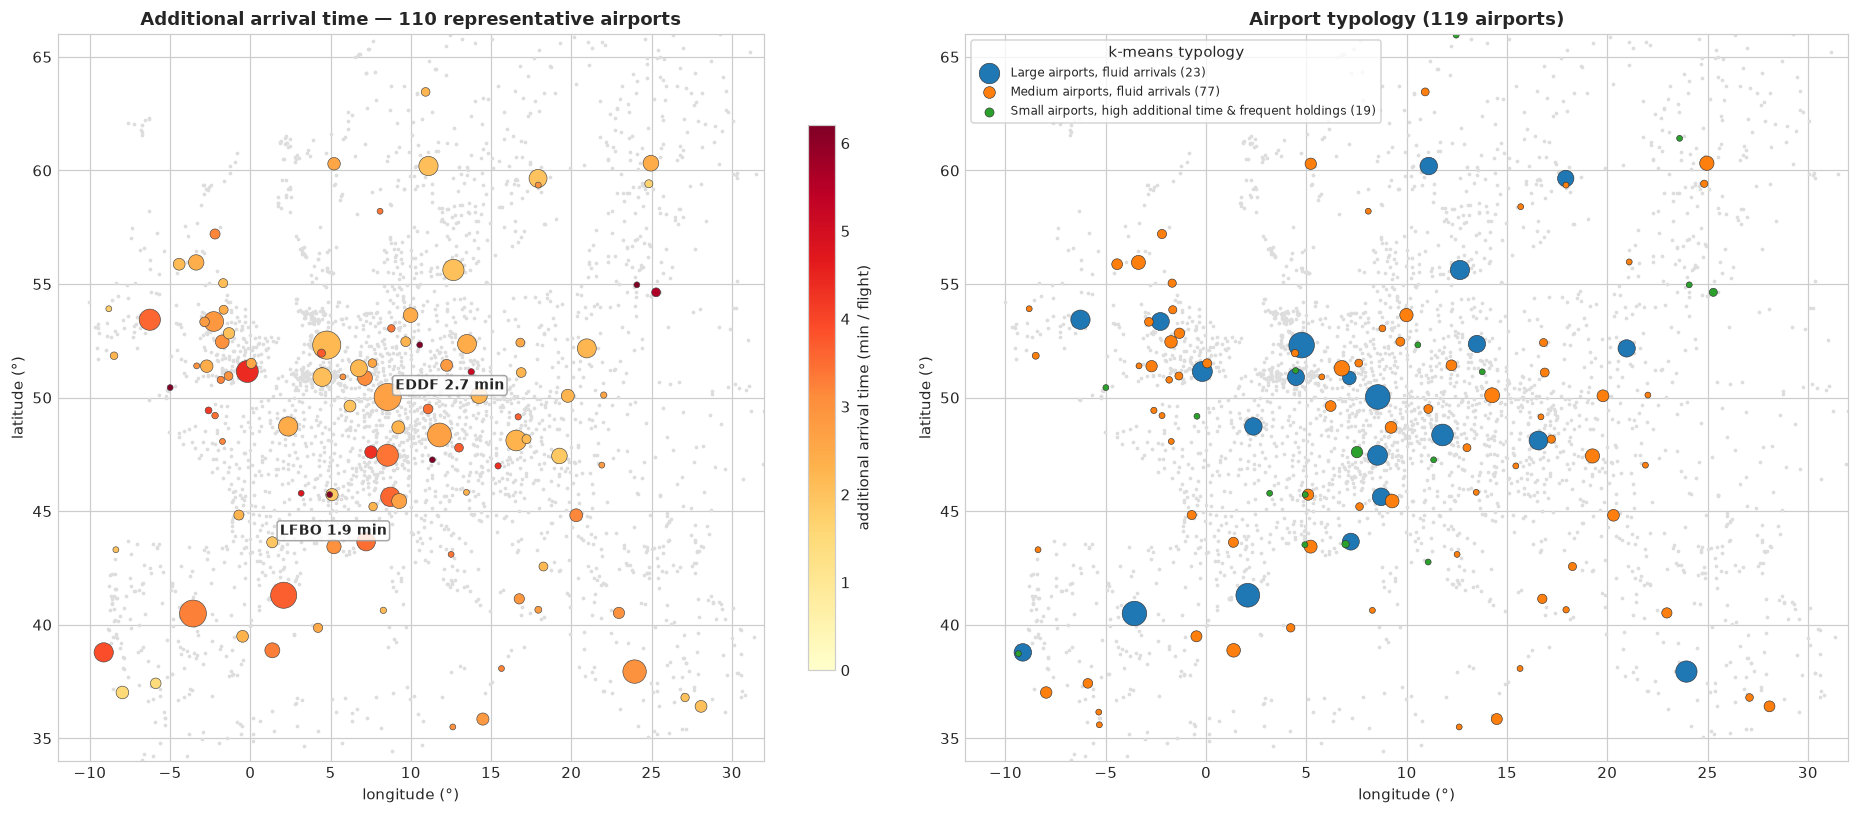

avg_daily_arrivals          \
                                                                count    mean   
cluster_label                                                                   
Large airports, fluid arrivals                                     23  401.25   
Medium airports, fluid arrivals                                    77   88.11   
Small airports, high additional time & frequent...                 19   31.82   

                                                   avg_additional_min        \
                                                                count  mean   
cluster_label                                                                 
Large airports, fluid arrivals                                     23  2.92   
Medium airports, fluid arrivals                                    77  2.65   
Small airports, high additional time & frequent...                 19  6.09   

                                                   pct_with_holding        \
                                                              count  mean   
cluster_label                                                               
Large airports, fluid arrivals                                   23  1.71   
Medium airports, fluid arrivals                                  77  1.31   
Small airports, high additional time & frequent...               19  2.39   

                                                   avg_level_minutes        
                                                               count  mean  
cluster_label                                                               
Large airports, fluid arrivals                                    23  2.54  
Medium airports, fluid arrivals                                   77  2.22  
Small airports, high additional time & frequent...                19  2.90

In [4]:
pos = airports.set_index("airport_icao")[["latitude", "longitude"]]
rep = summary[(summary["measured"] >= MIN_MEASURED) & (summary["coverage_pct"] >= 30)].join(pos, how="inner")
background = airports[airports["longitude"].between(-12, 32) & airports["latitude"].between(34, 66)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7.5))
for ax in (ax1, ax2):
    ax.scatter(background["longitude"], background["latitude"], s=2, color="#dddddd")
    ax.set_xlim(-12, 32); ax.set_ylim(34, 66); ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)")
vmax = rep["additional_min"].quantile(0.95)
sc = ax1.scatter(rep["longitude"], rep["latitude"], c=rep["additional_min"].clip(upper=vmax), cmap="YlOrRd",
                 vmin=0, vmax=vmax, s=np.clip(rep["arrivals"] / 120, 15, 350), edgecolors="#444444", linewidths=0.4)
fig.colorbar(sc, ax=ax1, shrink=0.75, label="additional arrival time (min / flight)")
for icao in FOCUS:
    if icao in rep.index:
        r = rep.loc[icao]
        ax1.annotate(f"{icao} {r['additional_min']:.1f} min", (r["longitude"], r["latitude"]), xytext=(5, 5),
                     textcoords="offset points", fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#999999", alpha=0.85))
ax1.set_title(f"Additional arrival time — {len(rep)} representative airports", fontweight="bold")

if not typology.empty:
    t = typology.set_index("airport_icao").join(pos, how="inner")
    for (label, grp), colour in zip(t.groupby("cluster_label"), sns.color_palette("tab10")):
        ax2.scatter(grp["longitude"], grp["latitude"], s=np.clip(grp["avg_daily_arrivals"] * 0.4, 15, 300),
                    color=colour, edgecolors="#333333", linewidths=0.4, label=f"{label} ({len(grp)})")
    ax2.legend(loc="upper left", fontsize=8, frameon=True, title="k-means typology")
    ax2.set_title(f"Airport typology ({len(t)} airports)", fontweight="bold")
plt.tight_layout(); save(fig, "01_europe_additional_time_and_typology"); plt.show()
if not typology.empty:
    display(typology.groupby("cluster_label")[["avg_daily_arrivals", "avg_additional_min", "pct_with_holding",
                                                "avg_level_minutes"]].agg(["count", "mean"]).round(2))

## 3. Where do aircraft hold? Heathrow and Paris-CDG

Holding patterns detected in the data (0.1° cells, size and colour = minutes of holding), with the 40 NM and 100 NM circles.

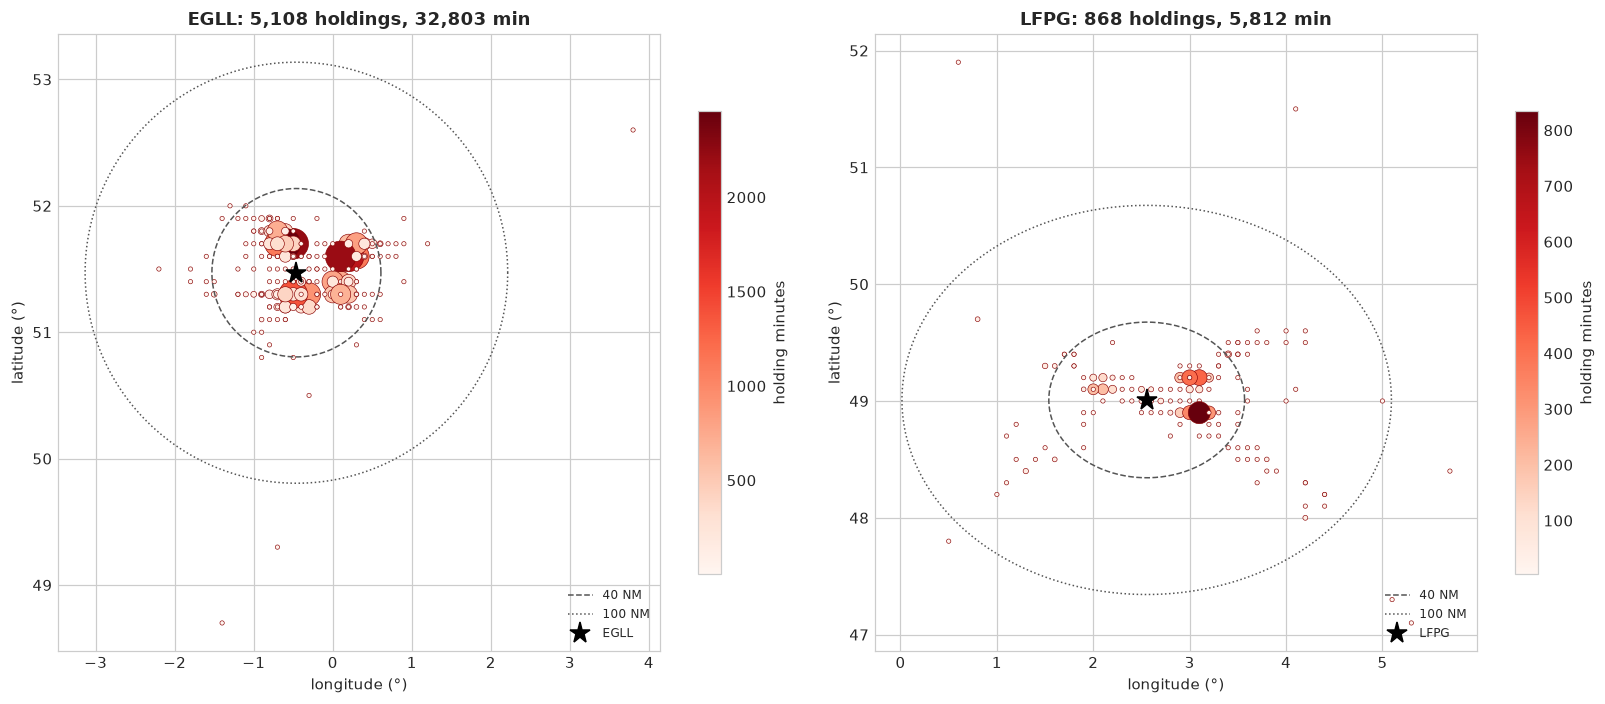

In [5]:
def holding_map(icao, ax):
    lat0, lon0 = pos.loc[icao]
    h = hotspots[hotspots["airport_icao"] == icao]
    theta = np.linspace(0, 2 * np.pi, 200)
    for nm, style in [(40, "--"), (100, ":")]:
        r = nm * 1.852 / 111.2
        ax.plot(lon0 + r * np.cos(theta) / np.cos(np.radians(lat0)), lat0 + r * np.sin(theta), style,
                color="#555555", lw=1, label=f"{nm} NM")
    sc = ax.scatter(h["lon_cell"], h["lat_cell"], s=np.clip(h["holding_minutes"] / 4, 8, 400),
                    c=h["holding_minutes"], cmap="Reds", edgecolors="#880000", linewidths=0.4)
    ax.plot(lon0, lat0, "k*", ms=14, label=icao)
    ax.set_title(f"{icao}: {h['holdings'].sum():,} holdings, {h['holding_minutes'].sum():,.0f} min", fontweight="bold")
    ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)"); ax.legend(loc="lower right", fontsize=8)
    return sc

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for icao, ax in zip(["EGLL", "LFPG"], axes):
    fig.colorbar(holding_map(icao, ax), ax=ax, shrink=0.75, label="holding minutes")
plt.tight_layout(); save(fig, "02_holding_hotspots_egll_lfpg"); plt.show()

## 4. When is time lost? Hour of the day × day of the week

Average additional time (weighted by measured flights, complete hours only, same colour scale for all airports). Cells with fewer than 20 measured flights are left blank. Times in UTC.

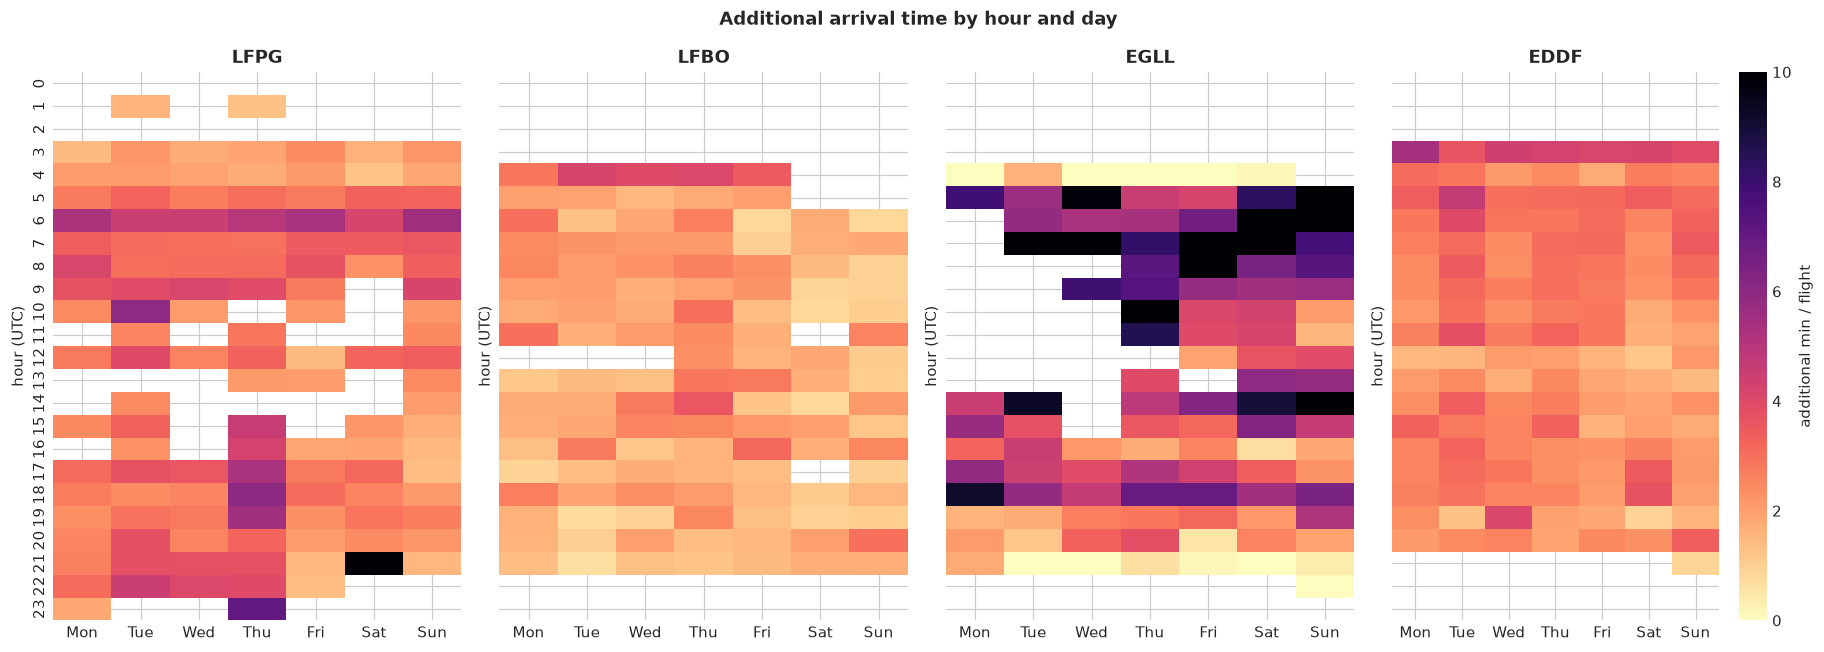

In [6]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hc = hourly[hourly["is_complete_hour"] & (hourly["arrivals_measured"] > 0)].copy()
hc["day"] = pd.to_datetime(hc["movement_date"]).dt.dayofweek.map(dict(enumerate(DAYS)))
hc["w_add"] = hc["avg_additional_min"] * hc["arrivals_measured"]
shown = [a for a in FOCUS if a in summary.index and summary.loc[a, "measured"] >= MIN_MEASURED]

fig, axes = plt.subplots(1, max(len(shown), 1), figsize=(4.2 * max(len(shown), 1), 6), sharey=True)
for ax, icao in zip(np.atleast_1d(axes), shown):
    s = hc[hc["airport_icao"] == icao].groupby(["movement_hour", "day"])[["w_add", "arrivals_measured"]].sum()
    grid = (s["w_add"] / s["arrivals_measured"]).where(s["arrivals_measured"] >= 20).unstack()
    grid = grid.reindex(index=range(24), columns=DAYS)
    sns.heatmap(grid, ax=ax, cmap="magma_r", vmin=0, vmax=10, cbar=ax is np.atleast_1d(axes)[-1],
                cbar_kws={"label": "additional min / flight"})
    ax.set_title(icao, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("hour (UTC)")
fig.suptitle("Additional arrival time by hour and day", fontweight="bold")
plt.tight_layout(); save(fig, "03_hour_day_heatmaps"); plt.show()

## 5. Saturation: hourly demand vs additional time

For each airport, the complete hours are grouped by number of arrivals (bins of 5); the line is the flight-weighted mean additional time, the band ± 1 standard error. Bins with fewer than 30 measured flights are not drawn.

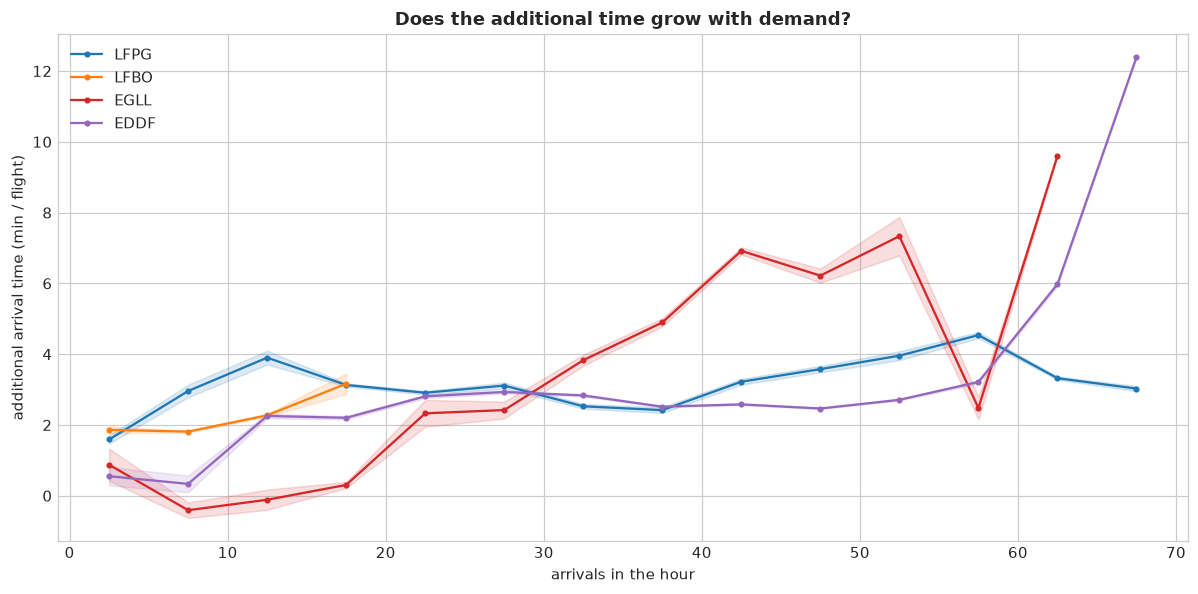

bin,2.5,7.5,12.5,17.5,22.5,27.5,32.5,37.5,42.5,47.5,52.5,57.5,62.5,67.5
LFPG,1.6,3.0,3.9,3.1,2.9,3.1,2.5,2.4,3.2,3.6,4.0,4.5,3.3,3.0
LFBO,1.9,1.8,2.3,3.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EGLL,0.9,-0.4,-0.1,0.3,2.3,2.4,3.8,4.9,6.9,6.2,7.3,2.5,9.6,NaN
EDDF,0.6,0.3,2.3,2.2,2.8,2.9,2.8,2.5,2.6,2.5,2.7,3.2,6.0,12.4


In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
curves = {}
for icao in shown:
    x = hc[hc["airport_icao"] == icao].copy()
    x["bin"] = (x["arrivals"] // 5) * 5 + 2.5
    b = x.groupby("bin").apply(lambda z: pd.Series({
        "mean": np.average(z["avg_additional_min"], weights=z["arrivals_measured"]),
        "sd": np.sqrt(np.cov(z["avg_additional_min"], aweights=z["arrivals_measured"])) if len(z) > 1 else 0.0,
        "n": z["arrivals_measured"].sum()}))
    b = b[b["n"] >= 30]
    curves[icao] = b
    se = b["sd"] / np.sqrt(b["n"].clip(lower=1))
    ax.plot(b.index, b["mean"], "-o", ms=3, color=COLORS[icao], label=icao)
    ax.fill_between(b.index, b["mean"] - se, b["mean"] + se, color=COLORS[icao], alpha=0.15)
ax.set_xlabel("arrivals in the hour"); ax.set_ylabel("additional arrival time (min / flight)")
ax.set_title("Does the additional time grow with demand?", fontweight="bold"); ax.legend()
plt.tight_layout(); save(fig, "04_saturation_curves"); plt.show()
pd.concat({k: v["mean"].round(1) for k, v in curves.items()}, axis=1).T

## 6. Real descent profiles: continuous descent vs level-offs and holding

Four real arrivals of the period (from `silver/arrivals` and `silver/flight_events`): at Heathrow and Paris-CDG, the flight with the median holding time among those that held, and a flight without any level-off. Altitude against minutes before the runway; the level-offs found by the pipeline are highlighted.

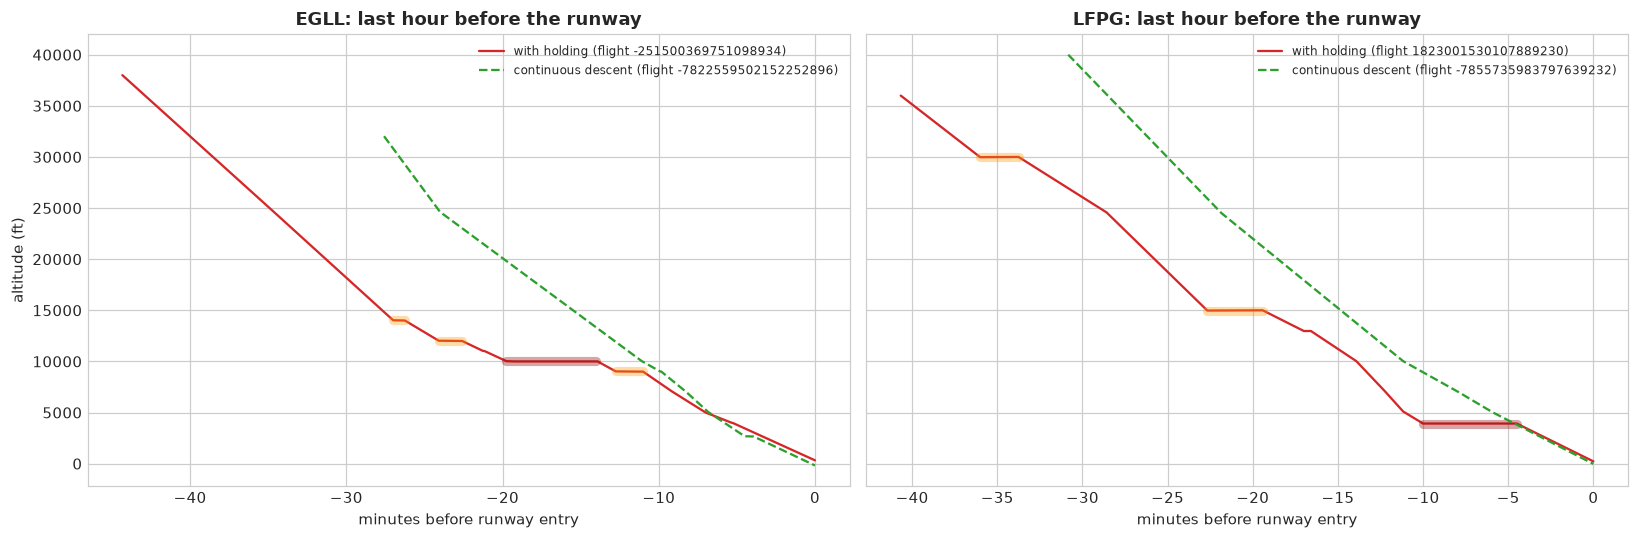

thick segments: level-offs found by the pipeline (dark red = holding pattern)


In [8]:
from pyspark.sql import functions as F

arr = spark.read.parquet(str(settings.silver_dir / "arrivals"))
lev = spark.read.parquet(str(settings.silver_dir / "descent_level_offs"))
picked = {}
for icao in ["EGLL", "LFPG"]:
    a = arr.filter((F.col("dest_icao") == icao) & F.col("is_transit_plausible"))
    held = a.filter("holding_count > 0").select("flight_id", "holding_minutes").toPandas()
    if len(held):
        med = held.iloc[(held["holding_minutes"] - held["holding_minutes"].median()).abs().argsort()[:1]]
        picked[(icao, "with holding")] = int(med["flight_id"].iloc[0])
    smooth = a.filter("level_off_count = 0").select("flight_id").limit(1).toPandas()
    if len(smooth):
        picked[(icao, "continuous descent")] = int(smooth["flight_id"].iloc[0])

ids = list(picked.values())
landing = arr.filter(F.col("flight_id").isin(ids)).select("flight_id", "landing_utc").toPandas().set_index("flight_id")
events = (spark.read.parquet(str(settings.silver_dir / "flight_events"))
          .filter(F.col("flight_id").isin(ids) & F.col("altitude_ft").isNotNull())
          .select("flight_id", "event_timestamp_utc", "altitude_ft").toPandas())
levels = lev.filter(F.col("flight_id").isin(ids)).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, icao in zip(axes, ["EGLL", "LFPG"]):
    for (apt, kind), fid in picked.items():
        if apt != icao:
            continue
        t0 = landing.loc[fid, "landing_utc"]
        e = events[events["flight_id"] == fid].sort_values("event_timestamp_utc")
        e = e.assign(m=(e["event_timestamp_utc"] - t0).dt.total_seconds() / 60)
        e = e[e["m"].between(-60, 0)]
        style = "-" if kind == "with holding" else "--"
        ax.plot(e["m"], e["altitude_ft"], style, color="#d62728" if kind == "with holding" else "#2ca02c",
                label=f"{kind} (flight {fid})")
        for _, l in levels[levels["flight_id"] == fid].iterrows():
            s, f = ((l["start_utc"] - t0).total_seconds() / 60, (l["end_utc"] - t0).total_seconds() / 60)
            ax.plot([s, f], [l["altitude_ft"]] * 2, lw=6, alpha=0.35,
                    color="#8b0000" if l["is_holding"] else "#ff9900")
    ax.set_title(f"{icao}: last hour before the runway", fontweight="bold")
    ax.set_xlabel("minutes before runway entry"); ax.legend(fontsize=8)
axes[0].set_ylabel("altitude (ft)")
plt.tight_layout(); save(fig, "05_real_descent_profiles"); plt.show()
print("thick segments: level-offs found by the pipeline (dark red = holding pattern)")

## 7. The five airports side by side

Level-off minutes per arrival by flight-level band, share of arrivals with a holding pattern, and the fuel **hypothesis** (12.7 kg per minute of level flight).

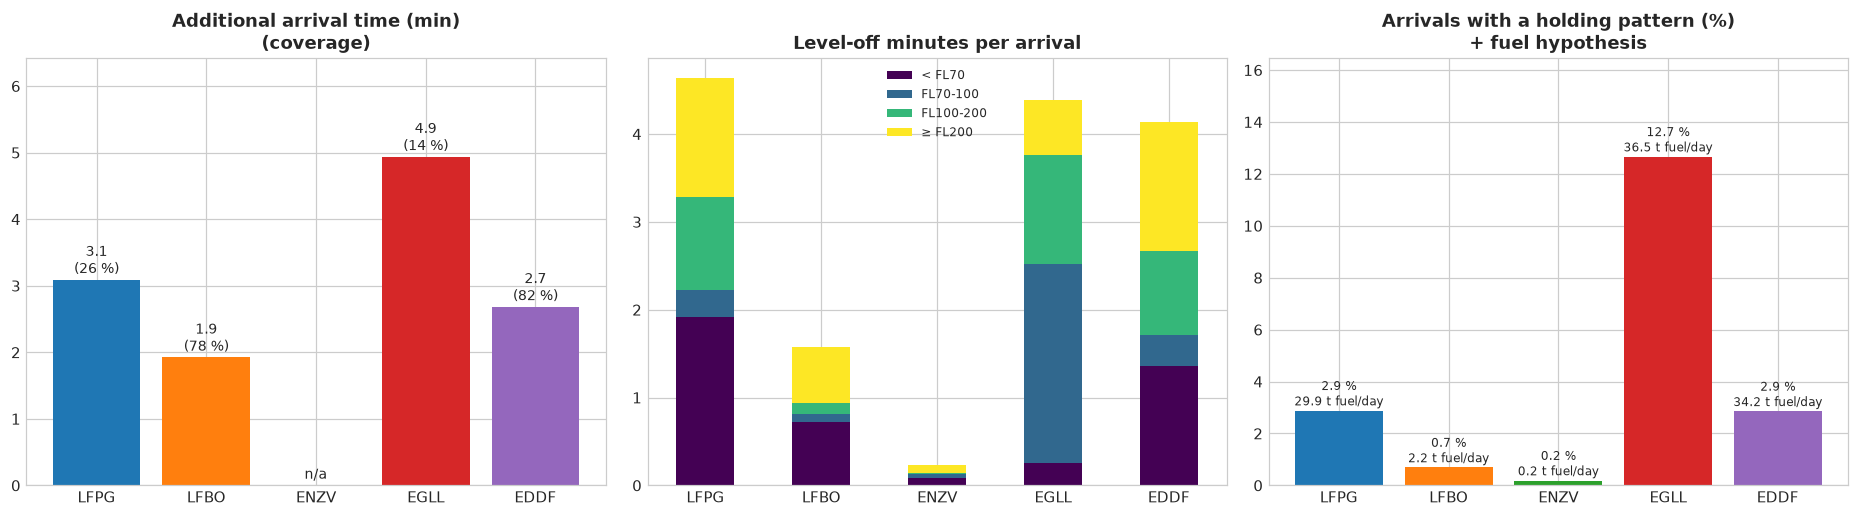

In [9]:
bands = {"level_minutes_lt_fl70": "< FL70", "level_minutes_fl70_100": "FL70-100",
         "level_minutes_fl100_200": "FL100-200", "level_minutes_ge_fl200": "≥ FL200"}
fd = daily[daily["airport_icao"].isin(FOCUS)]
per_arr = fd.groupby("airport_icao")[list(bands) + ["arrivals"]].sum()
per_arr = per_arr[list(bands)].div(per_arr["arrivals"], axis=0).rename(columns=bands).reindex(key.index)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4.8))
a1.bar(key.index, key["additional_min"].fillna(0), color=[COLORS[i] for i in key.index])
for i, (icao, r) in enumerate(key.iterrows()):
    a1.text(i, (r["additional_min"] if pd.notna(r["additional_min"]) else 0) + 0.1,
            f"{r['additional_min']:.1f}\n({r['coverage_pct']:.0f} %)" if pd.notna(r["additional_min"]) else "n/a",
            ha="center", fontsize=9)
a1.set_title("Additional arrival time (min)\n(coverage)", fontweight="bold")
a1.set_ylim(0, max(1.0, key["additional_min"].max(skipna=True) or 1) * 1.3)
per_arr.plot.bar(stacked=True, ax=a2, rot=0, colormap="viridis")
a2.set_title("Level-off minutes per arrival", fontweight="bold"); a2.legend(fontsize=8); a2.set_xlabel("")
a3.bar(key.index, key["pct_with_holding"], color=[COLORS[i] for i in key.index])
for i, (icao, r) in enumerate(key.iterrows()):
    a3.text(i, r["pct_with_holding"] + 0.2, f"{r['pct_with_holding']:.1f} %\n{r['fuel_t_per_day']:.1f} t fuel/day",
            ha="center", fontsize=8)
a3.set_title("Arrivals with a holding pattern (%)\n+ fuel hypothesis", fontweight="bold")
a3.set_ylim(0, max(1.0, key["pct_with_holding"].max()) * 1.3)
plt.tight_layout(); save(fig, "06_focus_airports"); plt.show()

## 8. What explains the additional time? Model and demand smoothing scenario

Gradient-boosted trees (Spark MLlib) trained on the first weeks and tested on the last 14 days, against a naive baseline (mean per airport and hour). The scenario caps each airport's hourly demand at its 90th percentile and moves the excess flights to the nearest hours with room (same day), then compares the predicted additional time. It is a simulation on an association model, not a causal prediction.

Model:    MAE 2.741 min | RMSE 4.437 | R² 0.135
Baseline: MAE 2.838 min | RMSE 4.642 | R² 0.053
Train 534,683 / test 200,937 arrivals, split at 2026-07-14 | published: True


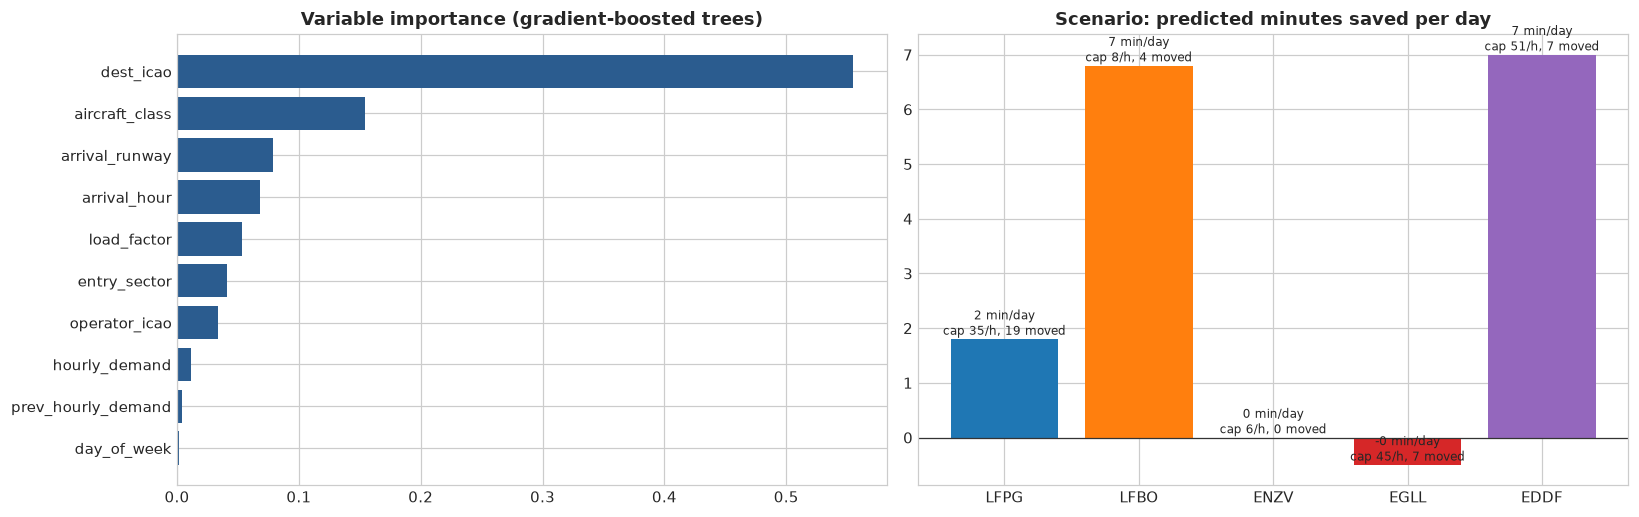

,airport_icao,scenario,demand_cap,measured_flights,flights_moved_per_day,predicted_total_min_before,predicted_total_min_after,saving_min_per_day
0,LFPG,CAP_P90_REDISTRIBUTE_SAME_DAY,35,1922,19.3,363.5,361.7,1.8
1,LFBO,CAP_P90_REDISTRIBUTE_SAME_DAY,8,1232,3.5,146.9,140.1,6.8
2,ENZV,CAP_P90_REDISTRIBUTE_SAME_DAY,6,1,0.0,3.9,3.9,0.0
3,EGLL,CAP_P90_REDISTRIBUTE_SAME_DAY,45,2351,7.1,827.3,827.8,-0.5
4,EDDF,CAP_P90_REDISTRIBUTE_SAME_DAY,51,8212,7.1,1480.7,1473.7,7.0


In [10]:
m = ml_report
if m:
    print(f"Model:    MAE {m.get('model_mae')} min | RMSE {m.get('model_rmse')} | R² {m.get('model_r2')}")
    print(f"Baseline: MAE {m.get('baseline_mae')} min | RMSE {m.get('baseline_rmse')} | R² {m.get('baseline_r2')}")
    print(f"Train {m.get('train_count'):,} / test {m.get('test_count'):,} arrivals, split at {m.get('split_date')} | "
          f"published: {m.get('beats_baseline')}")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))
if not feat_imp.empty:
    fi = feat_imp.sort_values("importance")
    a1.barh(fi["variable"], fi["importance"], color="#2b5c8f")
    a1.set_title("Variable importance (gradient-boosted trees)", fontweight="bold")
if not scenarios.empty:
    sc = scenarios.set_index("airport_icao").reindex([a for a in FOCUS if a in set(scenarios["airport_icao"])])
    a2.bar(sc.index, sc["saving_min_per_day"], color=[COLORS[i] for i in sc.index])
    for i, (icao, r) in enumerate(sc.iterrows()):
        a2.text(i, r["saving_min_per_day"], f"{r['saving_min_per_day']:.0f} min/day\ncap {r['demand_cap']}/h, "
                f"{r['flights_moved_per_day']:.0f} moved", ha="center", va="bottom", fontsize=8)
    a2.axhline(0, color="#333333", lw=0.8)
    a2.set_title("Scenario: predicted minutes saved per day", fontweight="bold")
plt.tight_layout(); save(fig, "07_model_and_scenario"); plt.show()
scenarios.drop(columns=["_ml_built_at_utc"], errors="ignore")

## 9. Conclusions

*Figures of the production run prod-8 on June–July 2026 (tables above). They are associations measured on open ADS-B data,
not causal proofs.*

**What we can measure.** Indicator B (level-offs, holdings) is available for almost every arrival; indicator A
(additional time) only where the runway entry is observed: 82 % of the arrivals at Frankfurt, 78 % at Toulouse,
26 % at Paris-CDG, 14 % at Heathrow and about 1 % at Stavanger. **Stavanger cannot be assessed with indicator A**
(48 measured arrivals: many short flights start inside the 100 NM circle and the runway is rarely seen); only its
descents can be described, and they are almost always continuous (0.2 min of level flight per arrival).

**How much time is lost?** Of the order of a few minutes per arrival: Toulouse 1.9 min, Frankfurt 2.7, Paris-CDG 3.1,
Heathrow 4.9 (on the 14 % of its arrivals that are measured). The level-offs in descent add up to 1.6 min per arrival
at Toulouse and 4.1–4.6 min at the three hubs.

**Where and when.** Heathrow stands out: 12.7 % of its arrivals fly a holding pattern (2.9 % at Paris-CDG and
Frankfurt, 0.7 % at Toulouse), concentrated in four zones around the airport, and its level-off time is mostly
between FL70 and FL100, the levels of its holding stacks. At Paris-CDG the holdings are mostly east of the airport.
At Heathrow the additional time **grows with demand**: about 0.2 min per flight below 20 arrivals per hour, 4.5 min
at 30–39, 6.8 min at 40–49; at Frankfurt (2.5–2.9 min between 20 and 59 arrivals per hour; it only rises in the few hours above 60) and Paris-CDG (2.4–4.3 min, no clear trend) it does not grow with the demand,
which suggests that their arrival capacity is better matched to the traffic. The morning wave (06–08 UTC) is the worst
period at Heathrow and Paris-CDG.

**Why — what the model says.** The gradient-boosted trees beat the naive baseline only slightly (MAE 2.74 vs 2.84
min on the last 14 days, R² 0.14 vs 0.05): most of the variance of the additional time is not explained by the data
we have (weather, runway configuration changes and ATC decisions are missing). Among the known factors, the airport
itself carries 55 % of the importance, the aircraft class 15 %, the runway 8 % and the hour of the day 7 %; the load
factor and the demand together about 7 %. Consistently, the demand smoothing scenario (hourly demand capped at the
airport's 90th percentile, excess flights moved to the nearest hours) saves almost nothing according to the model:
about 7 min per day at Frankfurt and Toulouse, 2 at Paris-CDG, none at Heathrow. This contradicts the clear saturation
curve of Heathrow (section 5): one model for 600+ airports, which only sees the 14 % of Heathrow arrivals that are
measured, does not capture an effect specific to one airport. Here the descriptive evidence is the stronger one; a
per-airport model, with weather, would be the next step. The typology (119 representative airports, 3 groups,
silhouette 0.55) separates large airports with fluid arrivals (23, e.g. Frankfurt, Amsterdam, Madrid, Munich, Gatwick),
medium airports with fluid arrivals (77, e.g. Toulouse) and 19 small airports with high additional time and frequent
holdings; Heathrow and Paris-CDG are not clustered (less than 30 % of their arrivals measured).

**What could be improved.**
1. *Heathrow*: the dependence on demand points to arrival flow management — spreading the peak arrivals of the
   morning wave, and sequencing them before they reach the holding stacks (extended arrival management).
2. *Paris-CDG, Frankfurt*: little holding, but 4–5 min of level flight per arrival in descent: continuous-descent
   procedures (and point-merge style sequencing) would reduce fuel burn more than flow management would. Under our
   hypothesis of 12.7 kg per minute, the level flight of the descents represents about 30 t of fuel per day at
   Paris-CDG and 34 t at Frankfurt.
3. *Toulouse, Stavanger*: fluid arrivals; nothing significant to gain on the arrival phase.

**Limits.** No schedules (no punctuality), no weather, partial coverage of the runway entry (biased towards the
airports and runways seen by the ground receivers), a reference that cannot see a delay suffered by almost every
flight of a group, and a fuel figure that is an average hypothesis, not an aircraft performance model.